In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='Species')

df = X.copy()
df['Species'] = y

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

print("\nSpecies Distribution:")
print(df['Species'].value_counts())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical Description:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Species Distribution:
Species
0    50
1    50
2    50
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [5]:
id3_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

id3_model.fit(X_train, y_train)

print("Decision Tree using Entropy trained successfully!")

Decision Tree using Entropy trained successfully!


In [6]:
y_pred_id3 = id3_model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values using ID3:")
print(y_pred_id3)

Actual Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted Values using ID3:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [7]:
accuracy_id3 = accuracy_score(y_test, y_pred_id3)

print("ID3 (Entropy) Accuracy:", accuracy_id3 * 100, "%")

ID3 (Entropy) Accuracy: 100.0 %


Confusion Matrix using ID3:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


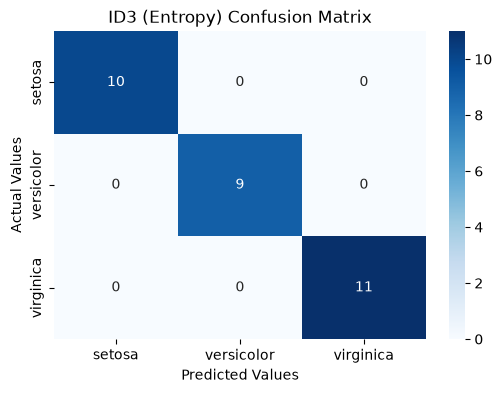

In [8]:
cm_id3 = confusion_matrix(y_test, y_pred_id3)

print("Confusion Matrix using ID3:")
print(cm_id3)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_id3,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("ID3 (Entropy) Confusion Matrix")
plt.show()


In [9]:
gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

gini_model.fit(X_train, y_train)

print("Decision Tree using Gini Index trained successfully!")

Decision Tree using Gini Index trained successfully!


In [10]:
y_pred_gini = gini_model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values using Gini Index:")
print(y_pred_gini)

Actual Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted Values using Gini Index:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [11]:
accuracy_gini = accuracy_score(y_test, y_pred_gini)

print("Gini Index Accuracy:", accuracy_gini * 100, "%")

Gini Index Accuracy: 100.0 %


Confusion Matrix using Gini Index:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


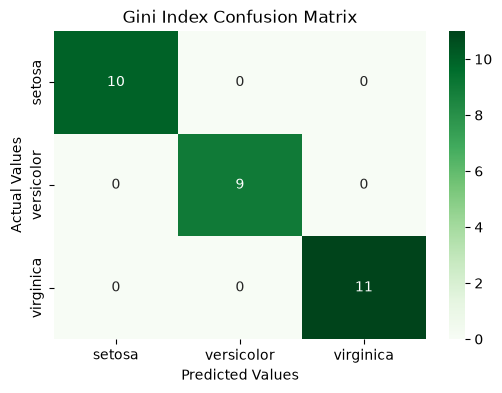

In [12]:
cm_gini = confusion_matrix(y_test, y_pred_gini)

print("Confusion Matrix using Gini Index:")
print(cm_gini)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_gini,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Gini Index Confusion Matrix")
plt.show()

In [13]:
comparison = pd.DataFrame({
    'Algorithm': ['ID3 (Entropy)', 'Gini Index'],
    'Accuracy': [
        accuracy_id3 * 100,
        accuracy_gini * 100
    ]
})

print(comparison)

       Algorithm  Accuracy
0  ID3 (Entropy)     100.0
1     Gini Index     100.0


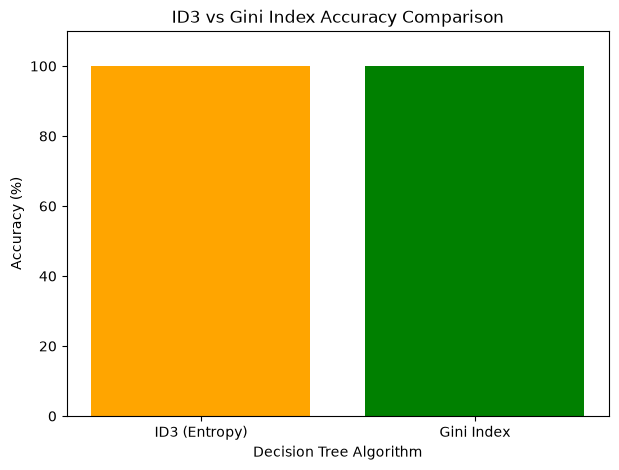

In [14]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison['Algorithm'],
    comparison['Accuracy'],
    color=['orange', 'green']
)

plt.xlabel("Decision Tree Algorithm")
plt.ylabel("Accuracy (%)")
plt.title("ID3 vs Gini Index Accuracy Comparison")
plt.ylim(0, 110)

plt.show()

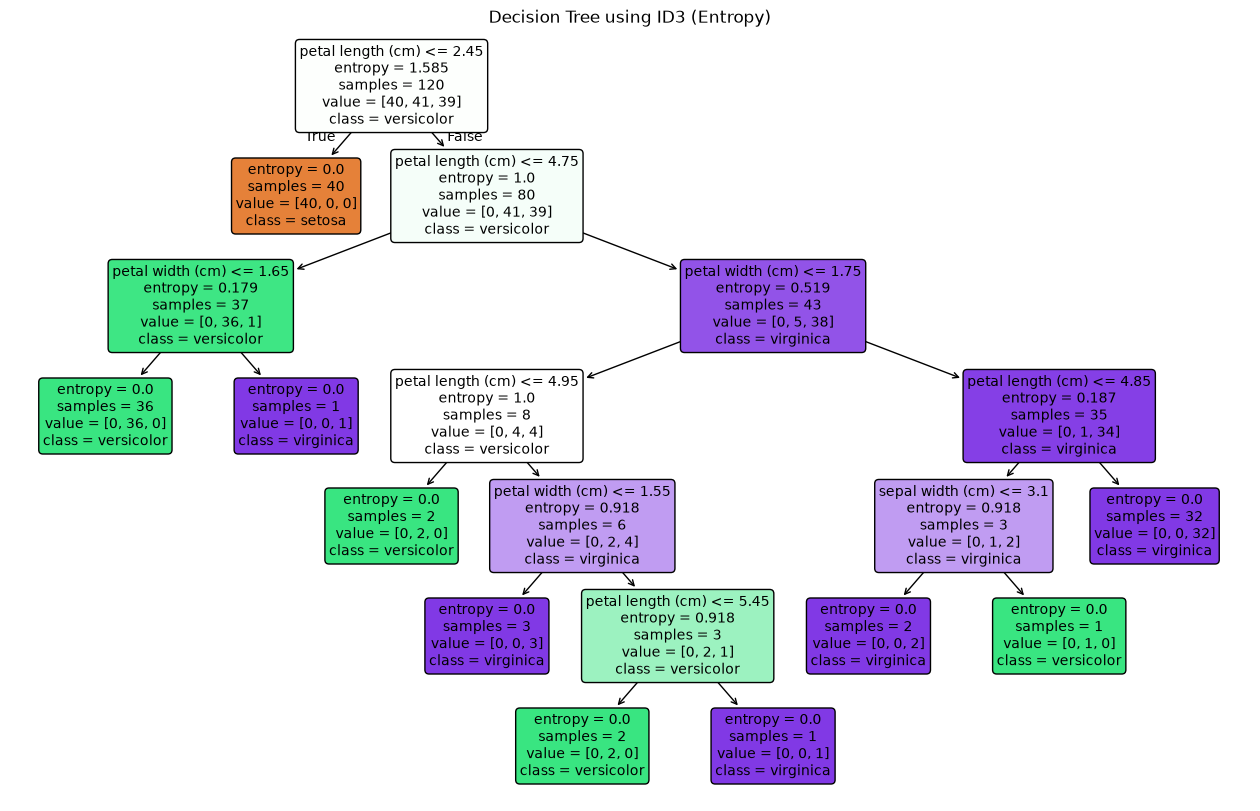

In [15]:
plt.figure(figsize=(16, 10))

plot_tree(
    id3_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree using ID3 (Entropy)")
plt.show()

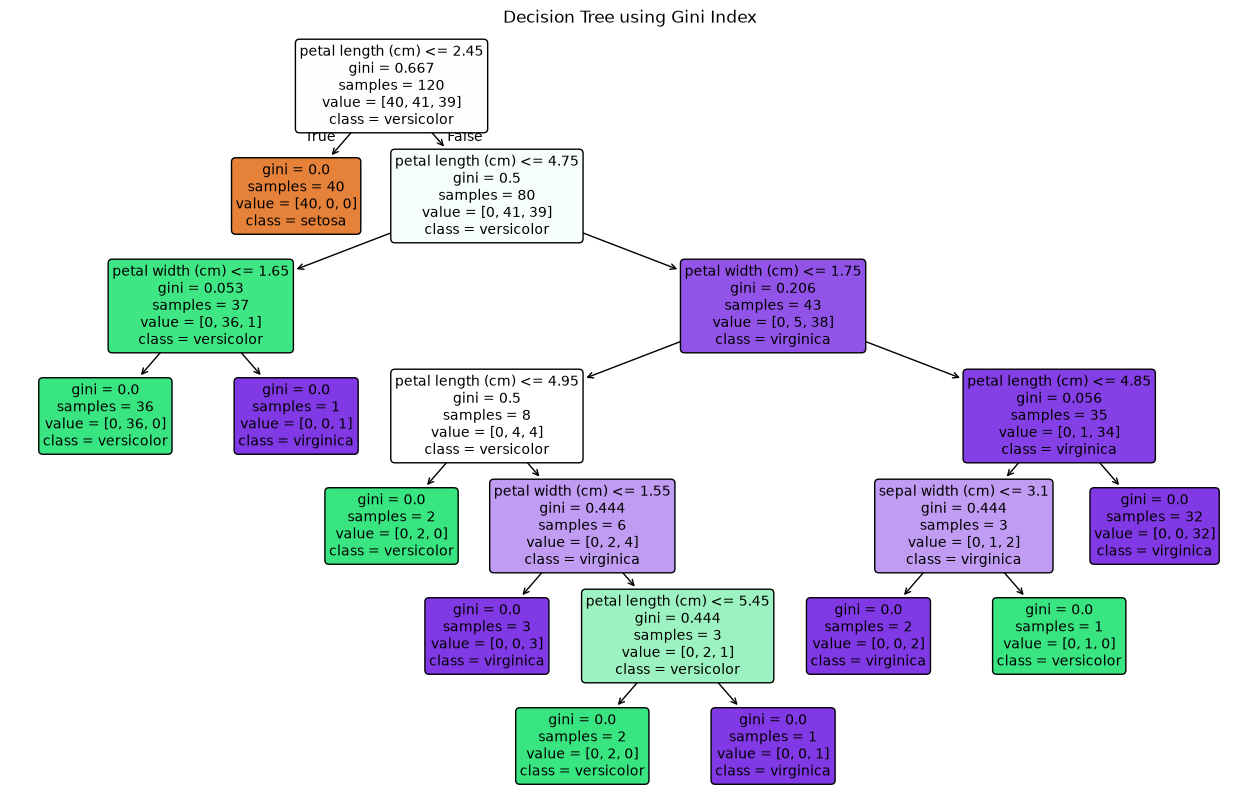

In [16]:
plt.figure(figsize=(16, 10))

plot_tree(
    gini_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree using Gini Index")
plt.show()

In [17]:
print("ID3 (Entropy) Classification Report:")
print(classification_report(y_test, y_pred_id3, target_names=iris.target_names))

print("\nGini Index Classification Report:")
print(classification_report(y_test, y_pred_gini, target_names=iris.target_names))

ID3 (Entropy) Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Gini Index Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

